# Imports

In [1]:
import torch
import torch.nn as nn
import torch.functional as F
import copy
from matplotlib import pyplot as plt
from tqdm import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

![ZipIt](../img/ZipIt.png)

# Classes

In [2]:
def unite_matrix(mat1: torch.Tensor, mat2: torch.Tensor) -> torch.Tensor:
    """Unite matrix A and B in block format:
        A 0
        0 B"""
    add1 = torch.zeros((mat1.shape[0], mat2.shape[1]), device=device)
    add2 = torch.zeros((mat2.shape[0], mat1.shape[1]), device=device)
    mat1 = torch.cat([mat1, add1], dim = 1)
    mat2 = torch.cat([add2, mat2], dim = 1)
    return torch.cat([mat1, mat2], dim=0)

class ZipLinear(nn.Linear):
    """Linear layer as a zipper method for two linear layers.
       While zipped == False, it behave as parallel linear layers.
       When zipped == True, it is zipped using ZipIt method.
    """
    def __init__(self, fc1: nn.Linear, fc2: nn.Linear):
        super().__init__(2 * fc1.in_features, 2 * fc1.out_features, fc1.bias is not None, device)
        self.weight = nn.Parameter(unite_matrix(fc1.weight, fc2.weight))
        self.M = None
        self.U = None
        self.prev_U = None
        self.zipped = False
        self.activations = []

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        y = nn.Linear.forward(self, x)
        if not self.zipped:
            self.activations.append(torch.stack([y]) if len(y.shape) == 1 else y)
        return y
    
    def build_MU(self):
        """Count M and U matrixes, using saved while training activations"""
        assert len(self.activations) > 0
        activations = torch.cat(self.activations, dim=0)
        corr_matrix = torch.corrcoef(activations.T)
        n = corr_matrix.shape[0] // 2

        matches = []
        used_i = set()
        used_j = set()
        for i in range(min(corr_matrix.shape)):
           corr_matrix[i, i] = -1e6
        
        for _ in range(n):
            max_idx = torch.argmax(corr_matrix)
            i, j = torch.unravel_index(max_idx, corr_matrix.shape)
            
            if i not in used_i and j not in used_j:
                matches.append((i, j))
                used_i.add(i)
                used_j.add(j)
                
                corr_matrix[i, :] = -1e6
                corr_matrix[j, :] = -1e6
                corr_matrix[:, i] = -1e6
                corr_matrix[:, j] = -1e6
            else:
                corr_matrix[i, j] = -1e6

        self.M = torch.zeros(n, 2 * n).to(device)
        for idx, (i, j) in enumerate(matches):
            self.M[idx, i] = 0.5
            self.M[idx, j] = 0.5
        self.U = 2 * self.M.T  
    
    def get_U(self):
        """Return U matrix (if built)"""
        assert self.U is not None
        return self.U
    
    def set_prev_U(self, prev_U):
        """Set prev U matrix for zipping method"""
        self.prev_U = prev_U

    def zip(self):
        """Zipper weight matrix with M and prev_U"""
        assert self.M is not None and self.prev_U is not None
        self.weight = nn.Parameter(self.M  @ self.weight @ self.prev_U)
        self.in_features, self.out_features = self.weight.shape
        self.zipped = True

In [3]:
class SimpleMLP(nn.Module):
    def __init__(self, in_features: int, hid_features: int, out_features: int, bias: bool = False, dtype = None):
        super().__init__()
        self.fc1 = nn.Linear(in_features, hid_features, bias=bias, dtype=dtype, device=device)
        self.act = nn.ReLU()
        self.fc2 = nn.Linear(hid_features, out_features, bias=bias, dtype=dtype, device=device)
        self.zipped = False
        self.U = None


    def forward_unzip(self, x: torch.Tensor):
        """Count forward and return features of model 1 and model 2 concated"""
        y = self.forward(x)
        # return torch.cat([y, y], dim=-1)
        if self.U is not None:
            return torch._C._nn.linear(y, self.U)
        else:
            return torch.cat([y, y], dim=-1)

    def forward(self, x: torch.Tensor):
        if self.zipped:
            x = torch.cat([x, x], dim = -1)
        x = self.fc1(x)
        x = self.act(x)
        x = self.fc2(x)
        return x

    def zip_with(self, other: 'SimpleMLP'):
        """Make an prezipped model with other"""
        self.fc1 = ZipLinear(self.fc1, other.fc1)
        self.fc2 = ZipLinear(self.fc2, other.fc2)
        self.zipped = True

    def train_with(self, train_data):
        """Run train data and eval M and U matrix"""
        # for x in train_data:
        #     self.forward(x)
        self.forward(train_data)
        self.fc1.build_MU()
        self.fc2.build_MU()

    def zip(self):
        """ZipIt operation"""
        U1 = self.fc1.get_U()
        self.U = self.fc2.get_U()
        self.fc1.set_prev_U(torch.cat(2 * [torch.eye(self.fc1.in_features // 2, device=device)]))
        self.fc2.set_prev_U(U1)
        self.fc1.zip()
        self.fc2.zip()
        self.zipped = False

# Utils

In [4]:
def count_mse(f, x, y):
    """Count MSE if f(x) and y"""
    return torch.mean((f(x) - y) ** 2)

def eval_merger(model1: SimpleMLP, model2: SimpleMLP, merged_model: SimpleMLP, data: torch.Tensor) -> torch.Tensor:
    """Count MSE of zipped model with two simple models"""
    return count_mse(merged_model.forward_unzip, data, torch.cat([model1.forward(data), model2.forward(data)], dim=-1))


In [5]:
def zipSimpleMLP(mlpA: SimpleMLP, mlpB: SimpleMLP, train_data: torch.Tensor, create_new: bool = True) -> SimpleMLP:
    """Take two SimpleMLP models, zipit using train data. Return zipped MLP"""
    new_mlp = mlpA
    if create_new:
        new_mlp = copy.deepcopy(mlpA)
    new_mlp.zip_with(mlpB)
    new_mlp.train_with(train_data)
    new_mlp.zip()
    return new_mlp

def avgSimpleMLP(mlpA: SimpleMLP, mlpB: SimpleMLP, train_data: torch.Tensor, create_new: bool = True) -> SimpleMLP:
    """Take two SimpleMLP models. Return same model with parameters averaged"""
    new_mlp = mlpA
    if create_new:
        new_mlp = copy.deepcopy(mlpA)
    new_dict = dict()
    dictA = mlpA.state_dict()
    dictB = mlpB.state_dict()
    for key in dictA.keys():
        new_dict[key] = (dictA[key] + dictB[key]) / 2
    new_mlp.load_state_dict(new_dict)
    return new_mlp
    

In [6]:
def find_mlp_mse_err(merger, n: int, hidden: int, out: int, examples: int = 10_000) -> torch.Tensor:
    """For a given merger make two random models, merge them, train and test on random data. Return it's MSE with original models"""
    mlp1 = SimpleMLP(n, hidden, out)
    mlp2 = SimpleMLP(n, hidden, out)

    x_train = torch.rand((examples, n), device=device)
    x_test = torch.rand((examples, n), device=device)

    mlp_merged = merger(mlp1, mlp2, x_train)

    res = eval_merger(mlp1, mlp2, mlp_merged, x_test)

    del mlp_merged, x_train, x_test, mlp1, mlp2
    torch.cuda.empty_cache()
    return res

In [7]:
def find_mlp_mse_err_repeat(merger, n: int, hidden: int, out: int, repeat: int = 1000) -> torch.Tensor:
    """Repeat previous test [repeat] times. Return a tensor of results"""
    return torch.stack([find_mlp_mse_err(merger, n, hidden, out, examples=repeat) for _ in tqdm(range(repeat))], dim=0).detach().cpu()

# Examples

In [8]:
mlp1 = SimpleMLP(2, 4, 2)
mlp2 = SimpleMLP(2, 4, 2)

x = torch.Tensor([[1, 2], [3, 4]]).to(device)
print("Model 1 output:")
print(mlp1.forward(x))
print("Model 1 output:")
print(mlp2.forward(x))

new_mlp = copy.deepcopy(mlp1)
new_mlp.zip_with(mlp2)

print()
print("First stage of zipping:")
print(new_mlp.forward(x))

Model 1 output:
tensor([[0.5547, 0.5956],
        [1.2657, 1.3591]], device='cuda:0', grad_fn=<MmBackward0>)
Model 1 output:
tensor([[ 0.0107, -0.2630],
        [ 0.0243, -0.5997]], device='cuda:0', grad_fn=<MmBackward0>)

First stage of zipping:
tensor([[ 0.5547,  0.5956,  0.0107, -0.2630],
        [ 1.2657,  1.3591,  0.0243, -0.5997]], device='cuda:0',
       grad_fn=<MmBackward0>)


In [9]:
print("Mean MSE for avg:")
res = torch.mean(torch.stack([find_mlp_mse_err(avgSimpleMLP, 10, 40, 2, examples = 100000) for _ in range(100)]))
print(res)

del res
torch.cuda.empty_cache()

Mean MSE for avg:
tensor(0.0134, device='cuda:0', grad_fn=<MeanBackward0>)


In [10]:
print("Mean MSE for zip:")
res = torch.mean(torch.stack([find_mlp_mse_err(zipSimpleMLP, 10, 40, 2, examples = 100000) for _ in range(100)]))
print(res)

del res
torch.cuda.empty_cache()

Mean MSE for zip:
tensor(0.0092, device='cuda:0', grad_fn=<MeanBackward0>)


In [11]:
res = find_mlp_mse_err_repeat(zipSimpleMLP, 1, 2, 3)
print(res[:20])

del res
torch.cuda.empty_cache()

100%|██████████| 1000/1000 [00:03<00:00, 297.34it/s]

tensor([6.2550e-04, 5.8651e-04, 1.0780e-02, 1.2195e-02, 4.0554e-03, 3.5708e-03,
        2.0228e-02, 1.7240e-02, 2.7514e-02, 2.8272e-02, 0.0000e+00, 7.2999e-03,
        2.9756e-05, 1.7149e-03, 1.4824e-02, 8.2455e-03, 1.6753e-03, 1.7730e-02,
        2.8299e-02, 1.5564e-02])


# Visualisation

In [12]:
VISUAL_TYPE_HIST = "Histogram"
VISUAL_TYPE_HIST_STACKED = "Histogram stack"
VISUAL_TYPE_CDF = "CDF"

In [13]:
def pr1(*x):
    return x[0]

def find_mlp_mse_err_visual(n, hidden, out, repeat = 1000, label = None, type = VISUAL_TYPE_HIST):
    zipit_results = find_mlp_mse_err_repeat(zipSimpleMLP, n, hidden, out, repeat)
    avg_results = find_mlp_mse_err_repeat(avgSimpleMLP, n, hidden, out, repeat)
    onevsone_results = find_mlp_mse_err_repeat(pr1, n, hidden, out, repeat)
    if type == VISUAL_TYPE_HIST:
        plt.hist([zipit_results, avg_results, onevsone_results], bins = 50)
    if type == VISUAL_TYPE_CDF:
        plt.hist([onevsone_results, avg_results, zipit_results], bins=200, density=True, cumulative=True, histtype='stepfilled', alpha=0.5)
    if type == VISUAL_TYPE_HIST_STACKED:
        plt.hist([zipit_results, avg_results, onevsone_results], bins=200, density=True, cumulative=True, histtype='barstacked', alpha=0.5)

    plt.legend(["ZipIt vs separates", "Average vs separates", "model 1 vs model 2"])

    if label is None:
        label = f"{type} MSE with n={n}, hidden={hidden}, out={out}"
    plt.title(label)
    plt.xlabel('MSE')
    plt.ylabel(type)
    plt.show()

    del zipit_results, avg_results
    torch.cuda.empty_cache()

100%|██████████| 1000/1000 [00:00<00:00, 1395.09it/s]


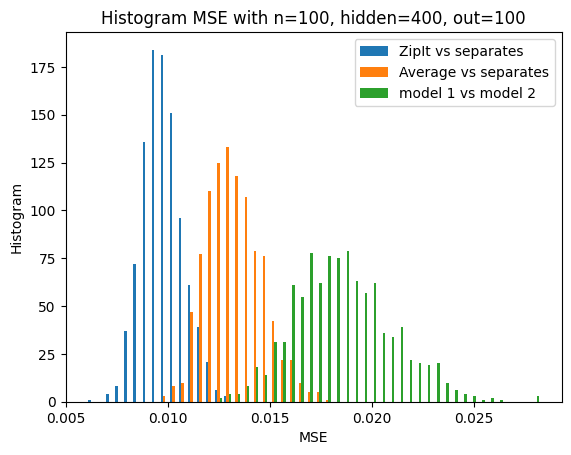

In [14]:
find_mlp_mse_err_visual(n=100, hidden=400, out=100, type=VISUAL_TYPE_HIST)

100%|██████████| 1000/1000 [00:00<00:00, 1417.89it/s]


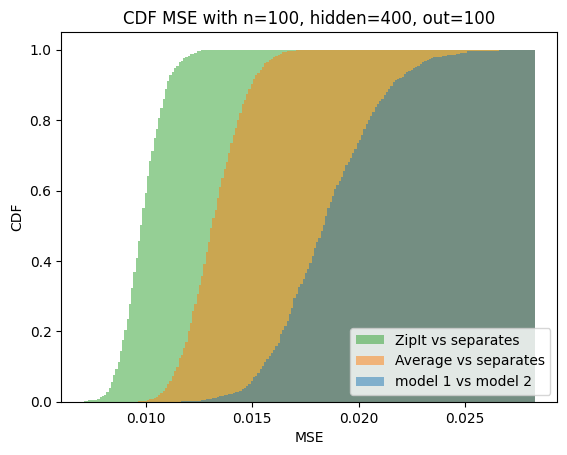

In [15]:
find_mlp_mse_err_visual(n=100, hidden=400, out=100, type=VISUAL_TYPE_CDF)

100%|██████████| 1000/1000 [00:00<00:00, 1030.28it/s]


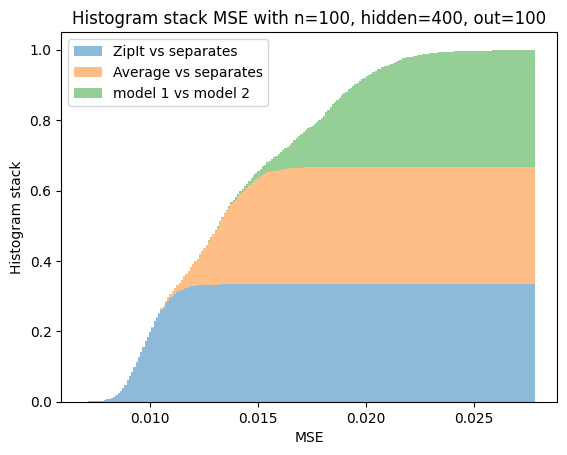

In [16]:
find_mlp_mse_err_visual(n=100, hidden=400, out=100, type=VISUAL_TYPE_HIST_STACKED)